Using DATA_DIR: /kaggle/input/datasets/sovitrath/diabetic-retinopathy-2015-data-colored-resized/colored_images/colored_images
Feature shape: (35126, 8206)
No_DR             25810
Moderate           5292
Mild               2443
Severe              873
Proliferate_DR      708
Name: count, dtype: int64
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'C': 10, 'solver': 'lbfgs'}
Best CV accuracy: 0.5575890678379697

Training Accuracy: 0.9923
                precision    recall  f1-score   support

          Mild       1.00      1.00      1.00      1710
      Moderate       0.95      1.00      0.98      3704
         No_DR       1.00      0.99      0.99     18067
Proliferate_DR       1.00      1.00      1.00       496
        Severe       1.00      1.00      1.00       611

      accuracy                           0.99     24588
     macro avg       0.99      1.00      0.99     24588
  weighted avg       0.99      0.99      0.99     24588



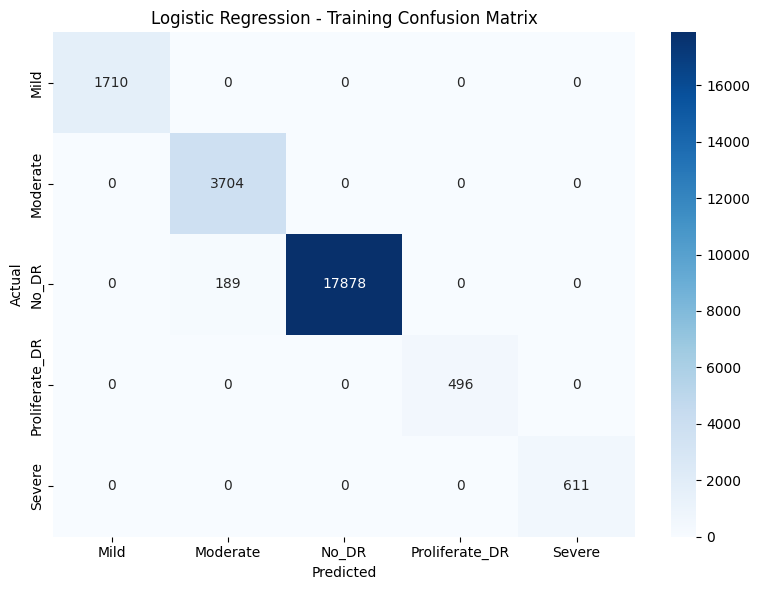


Validation Accuracy: 0.5286
                precision    recall  f1-score   support

          Mild       0.08      0.13      0.10       366
      Moderate       0.19      0.26      0.22       794
         No_DR       0.75      0.65      0.70      3872
Proliferate_DR       0.12      0.12      0.12       106
        Severe       0.09      0.11      0.10       131

      accuracy                           0.53      5269
     macro avg       0.25      0.25      0.25      5269
  weighted avg       0.59      0.53      0.56      5269



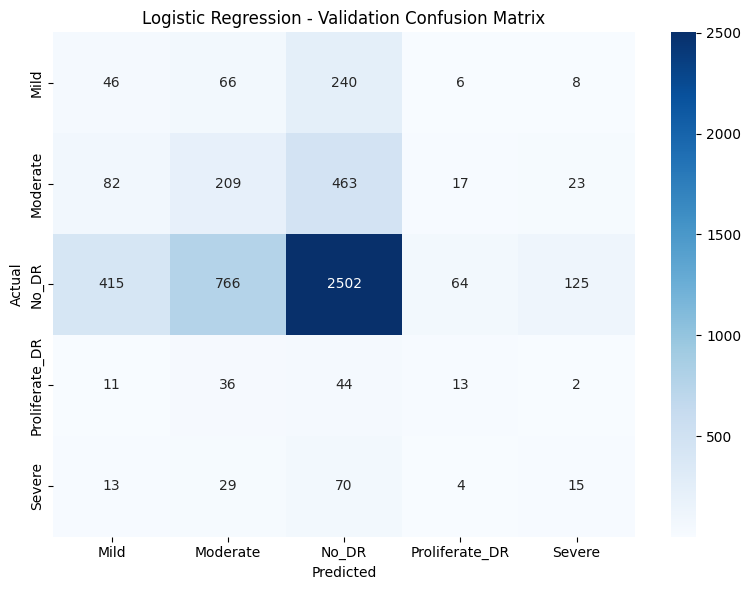


Testing Accuracy: 0.5305
                precision    recall  f1-score   support

          Mild       0.08      0.12      0.09       367
      Moderate       0.18      0.24      0.20       794
         No_DR       0.76      0.65      0.70      3871
Proliferate_DR       0.13      0.15      0.14       106
        Severe       0.07      0.09      0.08       131

      accuracy                           0.53      5269
     macro avg       0.24      0.25      0.24      5269
  weighted avg       0.60      0.53      0.56      5269



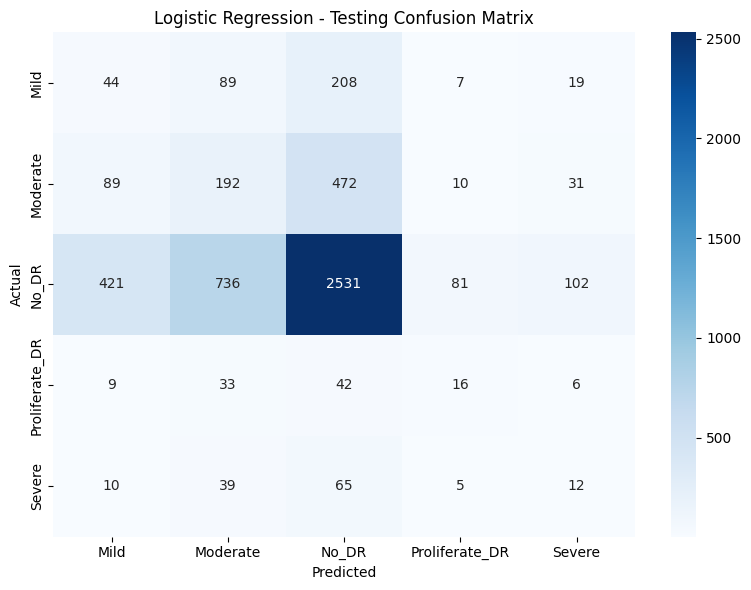


LOGISTIC REGRESSION RESULTS
      Dataset  Accuracy  Precision  Recall  F1 Score
0    Training    0.9923     0.9927  0.9923    0.9924
1  Validation    0.5286     0.5928  0.5286    0.5563
2     Testing    0.5305     0.5968  0.5305    0.5594


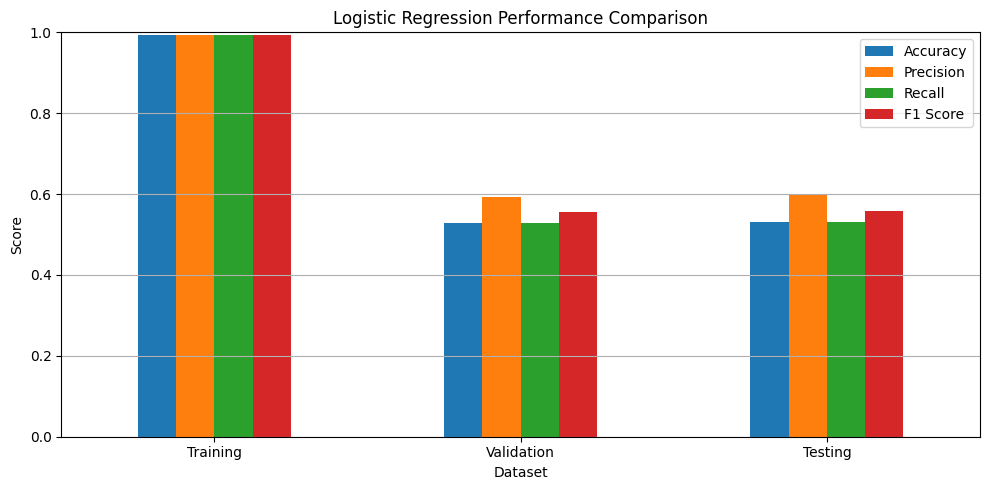

Logistic Regression experiment completed.


In [1]:
# ============================================================
# DIABETIC RETINOPATHY CLASSIFICATION USING LOGISTIC REGRESSION
# ============================================================

!pip -q install scikit-image

import os, cv2, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import hog, local_binary_pattern
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Configuration
DATA_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "No_DR" in dirs:
        DATA_DIR = root
        break

if DATA_DIR is None:
    raise FileNotFoundError("Dataset not attached! Click '+ Add Input' in the right sidebar and add the dataset.")

print("Using DATA_DIR:", DATA_DIR)

IMG_SIZE = 128
RANDOM_STATE = 42

# Feature extraction
X, y = [], []

class_names = sorted([
    d for d in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, d))
])

for class_name in class_names:
    folder = os.path.join(DATA_DIR, class_name)

    for filename in os.listdir(folder):
        image = cv2.imread(os.path.join(folder, filename))

        if image is None:
            continue

        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # HOG
        hog_feat = hog(
            gray, orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        # Color
        color_feat = []
        for channel in range(3):
            hist = cv2.calcHist(
                [rgb], [channel], None, [32], [0, 256]
            )
            color_feat.extend(cv2.normalize(hist, hist).flatten())

        # LBP
        lbp = local_binary_pattern(gray, 8, 1, method="uniform")
        lbp_hist, _ = np.histogram(
            lbp.ravel(), bins=10, range=(0, 10), density=True
        )

        combined = np.concatenate([hog_feat, color_feat, lbp_hist])

        X.append(combined)
        y.append(class_name)

X = np.array(X, dtype=np.float32)
y = np.array(y)

print("Feature shape:", X.shape)
print(pd.Series(y).value_counts())

# Data split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp,
    random_state=RANDOM_STATE
)

# Standardization
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Model tuning
model = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

parameters = {
    "C": [0.01, 0.1, 1, 10],
    "solver": ["lbfgs"]
}

grid = GridSearchCV(
    model, parameters,
    cv=3, scoring="accuracy",
    n_jobs=-1, verbose=1
)

grid.fit(X_train, y_train)
best_model = grid.best_estimator_

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)

# Evaluation
datasets = {
    "Training": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Testing": (X_test, y_test)
}

results = []

for name, (data, actual) in datasets.items():

    predicted = best_model.predict(data)

    acc = accuracy_score(actual, predicted)
    prec = precision_score(actual, predicted, average="weighted", zero_division=0)
    rec = recall_score(actual, predicted, average="weighted", zero_division=0)
    f1 = f1_score(actual, predicted, average="weighted", zero_division=0)

    results.append([name, acc, prec, rec, f1])

    print(f"\n{name} Accuracy: {acc:.4f}")
    print(classification_report(actual, predicted, zero_division=0))

    cm = confusion_matrix(actual, predicted, labels=class_names)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names
    )
    plt.title(f"Logistic Regression - {name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

# Results
results_df = pd.DataFrame(
    results, columns=["Dataset", "Accuracy", "Precision", "Recall", "F1 Score"]
)

print("\nLOGISTIC REGRESSION RESULTS")
print(results_df.round(4))

results_df.set_index("Dataset").plot(kind="bar", figsize=(10, 5))
plt.title("Logistic Regression Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# Save
os.makedirs("LogisticRegression_Output", exist_ok=True)

joblib.dump(best_model, "LogisticRegression_Output/lr_model.pkl")
joblib.dump(scaler, "LogisticRegression_Output/scaler.pkl")
joblib.dump(class_names, "LogisticRegression_Output/classes.pkl")
results_df.to_csv("LogisticRegression_Output/results.csv", index=False)

print("Logistic Regression experiment completed.")